# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!

Topics covered:
  - RAG architecture and pipeline
  - Document loading and preprocessing
  - Chunking strategies for optimal retrieval
  - Vector stores and similarity search
  - Generating answers with retrieved context


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for RAG architecture and pipeline.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [2]:

import re
from typing import Any, Dict, List


class ExampleClass:
    """
    Basic RAG architecture and pipeline.

    Pipeline stages:
    1. Document ingestion
    2. Text cleaning and chunking
    3. Keyword-based document retrieval
    4. Context-based response generation

    Note:
    This educational implementation uses keyword overlap rather than
    semantic embeddings and does not call a generative language model.
    """

    def __init__(self, chunk_size: int = 40, overlap: int = 5):
        if not isinstance(chunk_size, int) or isinstance(chunk_size, bool):
            raise TypeError("chunk_size must be an integer.")
        if not isinstance(overlap, int) or isinstance(overlap, bool):
            raise TypeError("overlap must be an integer.")
        if chunk_size < 1:
            raise ValueError("chunk_size must be greater than zero.")
        if overlap < 0 or overlap >= chunk_size:
            raise ValueError(
                "overlap must be non-negative and smaller than chunk_size."
            )

        self.chunk_size = chunk_size
        self.overlap = overlap
        self.data: List[Dict[str, Any]] = []

    def clean_text(self, text: str) -> str:
        """Normalize whitespace while preserving punctuation."""
        if not isinstance(text, str):
            raise TypeError("Document text must be a string.")
        if not text.strip():
            raise ValueError("Document text cannot be empty.")

        text = text.replace("\r\n", "\n").replace("\r", "\n")
        text = re.sub(r"[ \t]+", " ", text)
        text = re.sub(r"\n{3,}", "\n\n", text)

        return text.strip()

    def chunk_text(self, text: str) -> List[str]:
        """Split text into overlapping word-based chunks."""
        words = text.split()
        chunks = []
        start = 0

        while start < len(words):
            end = min(start + self.chunk_size, len(words))
            chunks.append(" ".join(words[start:end]))

            if end == len(words):
                break

            start = end - self.overlap

        return chunks

    def add_documents(self, documents: List[str]) -> int:
        """Clean, chunk, and store a list of documents."""
        if not isinstance(documents, list):
            raise TypeError("documents must be a list of strings.")
        if not documents:
            raise ValueError("documents cannot be an empty list.")

        new_chunks = []

        for doc_index, document in enumerate(documents):
            cleaned = self.clean_text(document)
            chunks = self.chunk_text(cleaned)

            for chunk_index, chunk in enumerate(chunks):
                new_chunks.append({
                    "document_id": doc_index,
                    "chunk_id": chunk_index,
                    "text": chunk
                })

        self.data.extend(new_chunks)
        return len(new_chunks)

    def retrieve(self, query: str, top_k: int = 3) -> List[Dict[str, Any]]:
        """Retrieve chunks ranked by query keyword overlap."""
        if not isinstance(query, str):
            raise TypeError("Query must be a string.")
        if not query.strip():
            raise ValueError("Query cannot be empty.")
        if not isinstance(top_k, int) or isinstance(top_k, bool):
            raise TypeError("top_k must be an integer.")
        if top_k < 1:
            raise ValueError("top_k must be at least 1.")
        if not self.data:
            raise ValueError(
                "The knowledge base is empty. Add documents before retrieval."
            )

        stopwords = {
            "the", "a", "an", "and", "or", "is", "are", "to",
            "of", "in", "for", "what", "how", "does", "do"
        }

        query_terms = {
            word for word in re.findall(r"\b\w+\b", query.lower())
            if word not in stopwords
        }

        if not query_terms:
            raise ValueError("Query contains no searchable keywords.")

        scored_chunks = []

        for chunk in self.data:
            chunk_terms = set(
                re.findall(r"\b\w+\b", chunk["text"].lower())
            )
            matched_terms = query_terms.intersection(chunk_terms)

            # Normalize by query length.
            score = len(matched_terms) / len(query_terms)

            if score > 0:
                scored_chunks.append({
                    **chunk,
                    "score": round(score, 4),
                    "matched_terms": sorted(matched_terms)
                })

        scored_chunks.sort(
            key=lambda item: item["score"],
            reverse=True
        )

        return scored_chunks[:top_k]

    def process(self, input_data: Any) -> Dict[str, Any]:
        """
        Process a question using the stored knowledge base.

        If input_data is a list of strings, ingest those documents.
        If input_data is a string, retrieve relevant chunks for that query.
        """
        if isinstance(input_data, list):
            count = self.add_documents(input_data)

            return {
                "status": "success",
                "action": "ingestion",
                "chunks_added": count,
                "total_chunks": len(self.data)
            }

        if isinstance(input_data, str):
            retrieved = self.retrieve(input_data)

            if not retrieved:
                answer = (
                    "I could not find relevant information in the "
                    "knowledge base to answer this question."
                )
            else:
                answer = "\n\n".join(
                    item["text"] for item in retrieved
                )

            return {
                "status": "success",
                "action": "retrieval",
                "query": input_data,
                "answer": answer,
                "sources": retrieved
            }

        raise TypeError(
            "input_data must be a query string or a list of document strings."
        )


# ------------------------------------------------
# Test 1: Ingest sample documents
# ------------------------------------------------

example = ExampleClass(chunk_size=20, overlap=3)

sample_documents = [
    (
        "A digital twin is a virtual representation of a physical asset. "
        "It uses sensor data to monitor equipment condition and performance."
    ),
    (
        "Predictive maintenance analyses sensor readings to identify "
        "possible equipment failures before they happen."
    ),
    (
        "A RAG pipeline retrieves relevant documents and uses the retrieved "
        "context to support answers to user questions."
    )
]

ingestion_result = example.process(sample_documents)
print("Ingestion result:")
print(ingestion_result)

assert ingestion_result["status"] == "success"
assert ingestion_result["chunks_added"] > 0


# ------------------------------------------------
# Test 2: Retrieve information
# ------------------------------------------------

query = "How does predictive maintenance use sensor data?"
result = example.process(query)

print("\nQuery result:")
print("Answer:", result["answer"])
print("Sources:", result["sources"])

assert result["status"] == "success"
assert result["action"] == "retrieval"
assert len(result["sources"]) > 0
assert "sensor" in result["answer"].lower()


# ------------------------------------------------
# Test 3: Invalid query
# ------------------------------------------------

try:
    example.process("   ")
except ValueError as error:
    print("\nEmpty query handled:", error)


# ------------------------------------------------
# Test 4: Invalid input type
# ------------------------------------------------

try:
    example.process(123)
except TypeError as error:
    print("\nInvalid input handled:", error)


# ------------------------------------------------
# Test 5: Retrieval before ingestion
# ------------------------------------------------

empty_system = ExampleClass()

try:
    empty_system.process("What is a digital twin?")
except ValueError as error:
    print("\nEmpty knowledge base handled:", error)


# ------------------------------------------------
# Test 6: Verify chunk overlap
# ------------------------------------------------

chunker = ExampleClass(chunk_size=4, overlap=1)
chunks = chunker.chunk_text("one two three four five six seven")

print("\nOverlap test:", chunks)

assert chunks[0].split()[-1] == chunks[1].split()[0]

print("\nAll tests passed.")

Ingestion result:
{'status': 'success', 'action': 'ingestion', 'chunks_added': 4, 'total_chunks': 4}

Query result:
Answer: Predictive maintenance analyses sensor readings to identify possible equipment failures before they happen.

A digital twin is a virtual representation of a physical asset. It uses sensor data to monitor equipment condition and
Sources: [{'document_id': 1, 'chunk_id': 0, 'text': 'Predictive maintenance analyses sensor readings to identify possible equipment failures before they happen.', 'score': 0.6, 'matched_terms': ['maintenance', 'predictive', 'sensor']}, {'document_id': 0, 'chunk_id': 0, 'text': 'A digital twin is a virtual representation of a physical asset. It uses sensor data to monitor equipment condition and', 'score': 0.4, 'matched_terms': ['data', 'sensor']}]

Empty query handled: Query cannot be empty.

Invalid input handled: input_data must be a query string or a list of document strings.

Empty knowledge base handled: The knowledge base is empty. Ad

---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Document loading and preprocessing.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [4]:
import json
import re
from typing import Any, Dict, List


def advanced_function(data: Any, **kwargs) -> Dict[str, Any]:
    """
    Load, clean, extract, chunk, and optionally search documents.

    Parameters
    ----------
    data : str, dict, or list
        A document string, a dictionary containing document text, or a list
        of strings and document dictionaries.
    **kwargs :
        chunk_size (int): Maximum words per chunk. Default is 100.
        overlap (int): Number of overlapping words. Default is 10.
        query (str): Optional keyword search query.
        top_k (int): Maximum number of search results. Default is 3.

    Returns
    -------
    dict
        Processed documents, chunks, extracted information, and search results.
    """

    # 1. Validate configuration
    chunk_size = kwargs.get("chunk_size", 100)
    if isinstance(chunk_size, bool) or not isinstance(chunk_size, int):
        raise TypeError("chunk_size must be an integer.")
    if chunk_size < 1:
        raise ValueError("chunk_size must be at least 1.")

    # If overlap is not explicitly provided, default to 10 but cap it to chunk_size - 1
    default_overlap = min(10, chunk_size - 1) if chunk_size > 1 else 0
    overlap = kwargs.get("overlap", default_overlap)

    if isinstance(overlap, bool) or not isinstance(overlap, int):
        raise TypeError("overlap must be an integer.")
    if overlap < 0 or overlap >= chunk_size:
        raise ValueError(
            "overlap must be at least 0 and smaller than chunk_size."
        )

    top_k = kwargs.get("top_k", 3)
    if isinstance(top_k, bool) or not isinstance(top_k, int):
        raise TypeError("top_k must be an integer.")
    if top_k < 1:
        raise ValueError("top_k must be at least 1.")

    query = kwargs.get("query")
    if query is not None:
        if not isinstance(query, str):
            raise TypeError("query must be a string.")
        if not query.strip():
            raise ValueError("query cannot be empty or contain only spaces.")

    # 2. Normalise input into a list of documents
    if isinstance(data, str):
        documents = [{"text": data, "metadata": {}}]
    elif isinstance(data, dict):
        documents = [data]
    elif isinstance(data, list):
        documents = data
    else:
        raise TypeError(
            "data must be a string, a document dictionary, or a list "
            "of strings and dictionaries."
        )

    if not documents:
        raise ValueError("data cannot be an empty list.")

    # 3. Clean document text while preserving technical punctuation
    def clean_text(text: str) -> str:
        if not isinstance(text, str):
            raise TypeError("Document text must be a string.")

        text = text.replace("\r\n", "\n").replace("\r", "\n")
        lines = [
            re.sub(r"[ \t]+", " ", line).strip()
            for line in text.split("\n")
        ]
        return re.sub(r"\n{3,}", "\n\n", "\n".join(lines)).strip()

    # 4. Extract useful structured information
    def extract_information(text: str) -> Dict[str, List[str]]:
        patterns = {
            "emails": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
            "urls": r"https?://[^\s<>\]\[\"']+",
            "dates": r"\b\d{4}-\d{2}-\d{2}\b",
            "error_codes": r"\bERR[-_]?\d+\b",
            "measurements": r"\b\d+(?:\.\d+)?\s?(?:ms|s|seconds|minutes|hours|%|GB|MB|KB)\b",
        }

        return {
            key: list(dict.fromkeys(re.findall(pattern, text, re.IGNORECASE)))
            for key, pattern in patterns.items()
        }

    # 5. Split text into overlapping word-based chunks
    def make_chunks(text: str) -> List[str]:
        words = text.split()

        if not words:
            return []

        chunks = []
        step = chunk_size - overlap

        for start in range(0, len(words), step):
            chunk_words = words[start:start + chunk_size]
            if chunk_words:
                chunks.append(" ".join(chunk_words))
            if start + chunk_size >= len(words):
                break

        return chunks

    # 6. Process and validate each document
    processed_documents = []
    all_chunks = []
    errors = []

    for index, item in enumerate(documents):
        try:
            if isinstance(item, str):
                raw_text = item
                metadata = {}
            elif isinstance(item, dict):
                raw_text = item.get("text", item.get("content"))
                metadata = item.get("metadata", {})

                if not isinstance(metadata, dict):
                    raise TypeError(
                        "The 'metadata' field must be a dictionary."
                    )
            else:
                raise TypeError(
                    "Each document must be a string or a dictionary."
                )

            if not isinstance(raw_text, str):
                raise TypeError(
                    "Each document must contain string 'text' or 'content'."
                )

            cleaned = clean_text(raw_text)

            if not cleaned:
                raise ValueError("Document text cannot be empty.")

            document_id = f"doc_{index + 1}"
            extracted = extract_information(cleaned)
            document_chunks = make_chunks(cleaned)

            processed_documents.append({
                "document_id": document_id,
                "text": cleaned,
                "metadata": metadata,
                "extracted_information": extracted,
                "word_count": len(cleaned.split()),
                "chunk_count": len(document_chunks),
            })

            for chunk_index, chunk in enumerate(document_chunks, start=1):
                all_chunks.append({
                    "document_id": document_id,
                    "chunk_id": f"{document_id}_chunk_{chunk_index}",
                    "text": chunk,
                    "metadata": metadata,
                })

        except (TypeError, ValueError) as exc:
            errors.append({
                "document_index": index,
                "error": str(exc),
            })

    if not processed_documents:
        raise ValueError(
            "No documents could be processed. Check the input format. "
            f"Errors: {errors}"
        )

    # 7. Optional keyword-based retrieval
    search_results = []

    if query is not None:
        query_terms = set(re.findall(r"\b\w+\b", query.lower()))

        for chunk in all_chunks:
            chunk_terms = set(
                re.findall(r"\b\w+\b", chunk["text"].lower())
            )
            matched_terms = sorted(query_terms.intersection(chunk_terms))

            if matched_terms:
                result = chunk.copy()
                result["matched_terms"] = matched_terms
                result["score"] = round(
                    len(matched_terms) / max(len(query_terms), 1), 3
                )
                search_results.append(result)

        search_results.sort(
            key=lambda item: (item["score"], len(item["matched_terms"])),
            reverse=True,
        )
        search_results = search_results[:top_k]

    # 8. Return results in a structured format
    return {
        "status": "success",
        "summary": {
            "documents_received": len(documents),
            "documents_processed": len(processed_documents),
            "documents_failed": len(errors),
            "total_chunks": len(all_chunks),
            "total_words": sum(
                doc["word_count"] for doc in processed_documents
            ),
        },
        "documents": processed_documents,
        "chunks": all_chunks,
        "search": {
            "query": query,
            "results_count": len(search_results),
            "results": search_results,
        },
        "errors": errors,
    }


# ============================================================
# TEST 1: A list of ordinary text documents
# ============================================================
sample_data = [
    "The digital twin uses sensor data to monitor equipment performance.",
    "Predictive maintenance can identify failures before they occur.",
    "Contact support@example.com if error ERR-404 occurs.",
]

output = advanced_function(
    sample_data,
    chunk_size=12,
    overlap=2,
    query="sensor equipment performance",
    top_k=3,
)

print("TEST 1: Text documents")
print(json.dumps(output, indent=2))

# ============================================================
# TEST 2: Documents with metadata
# ============================================================
metadata_data = [
    {
        "text": "System response time was 250 ms on 2026-10-14.",
        "metadata": {"source": "system_log.txt", "type": "log"},
    },
    {
        "content": "Read the report at https://example.com/report",
        "metadata": {"source": "report.md", "type": "report"},
    },
]

metadata_output = advanced_function(metadata_data, chunk_size=20)
print("\nTEST 2: Documents with metadata")
print(json.dumps(metadata_output["documents"], indent=2))

# ============================================================
# TEST 3: A single string
# ============================================================
single_output = advanced_function(
    "Digital twins combine real-world data with virtual models.",
    chunk_size=10,
)
print("\nTEST 3: Single string")
print(json.dumps(single_output["summary"], indent=2))

# ============================================================
# TEST 4: Invalid input and parameter handling
# ============================================================
test_cases = [
    ("Unsupported input type", lambda: advanced_function(123)),
    ("Empty document list", lambda: advanced_function([])),
    ("Invalid chunk size", lambda: advanced_function(["Text"], chunk_size=0)),
    ("Invalid overlap", lambda: advanced_function(
        ["Text"], chunk_size=5, overlap=5
    )),
    ("Empty search query", lambda: advanced_function(["Text"], query="  ")),
    ("Invalid document", lambda: advanced_function([123])),
]

print("\nTEST 4: Validation checks")

for test_name, test_function in test_cases:
    try:
        test_function()
        print(f"{test_name}: UNEXPECTED SUCCESS")
    except (TypeError, ValueError) as exc:
        print(f"{test_name}: PASS - {exc}")

# ============================================================
# TEST 5: Assertions for core functionality
# ============================================================
assert output["status"] == "success"
assert output["summary"]["documents_processed"] == 3
assert output["summary"]["total_chunks"] > 0
assert len(output["search"]["results"]) > 0

assert "support@example.com" in (
    output["documents"][2]["extracted_information"]["emails"]
)
assert "ERR-404" in (
    output["documents"][2]["extracted_information"]["error_codes"]
)

print("\nAll core functionality tests passed.")

TEST 1: Text documents
{
  "status": "success",
  "summary": {
    "documents_received": 3,
    "documents_processed": 3,
    "documents_failed": 0,
    "total_chunks": 3,
    "total_words": 24
  },
  "documents": [
    {
      "document_id": "doc_1",
      "text": "The digital twin uses sensor data to monitor equipment performance.",
      "metadata": {},
      "extracted_information": {
        "emails": [],
        "urls": [],
        "dates": [],
        "error_codes": [],
        "measurements": []
      },
      "word_count": 10,
      "chunk_count": 1
    },
    {
      "document_id": "doc_2",
      "text": "Predictive maintenance can identify failures before they occur.",
      "metadata": {},
      "extracted_information": {
        "emails": [],
        "urls": [],
        "dates": [],
        "error_codes": [],
        "measurements": []
      },
      "word_count": 8,
      "chunk_count": 1
    },
    {
      "document_id": "doc_3",
      "text": "Contact support@example.co

---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

In [5]:
%pip install matplotlib

2026-10-14 11:01:11,776 | WARNING | DigitalTwin.136549368318336 | Threshold exceeded: asset=Machine-01 sensor=temperature value=92.0 threshold=80.0
2026-10-14 11:01:11,777 | WARNING | DigitalTwin.136549368318336 | Threshold exceeded: asset=Machine-02 sensor=pressure value=230.0 threshold=200.0
2026-10-14 11:01:11,779 | WARNING | DigitalTwin.136549368318336 | Sensor reading 0 rejected: Sensor value must be a finite number.
2026-10-14 11:01:11,781 | ERROR | DigitalTwin.136549368318336 | Processing failed: Unknown operation type. Use documents, sensors, query or file.
2026-10-14 11:01:11,784 | WARNING | DigitalTwin.136549368318336 | Document item 0 rejected: Document text cannot be empty.
2026-10-14 11:01:11,785 | ERROR | DigitalTwin.136549368318336 | No valid documents were ingested.


All tests passed.

System statistics:
{
  "documents": 4,
  "chunks": 6,
  "total_words": 44,
  "estimated_tokens": 82,
  "sensor_readings": 3,
  "sensor_types": {
    "temperature": 1,
    "vibration": 1,
    "pressure": 1
  },
  "anomalies": 2,
  "errors_recorded": 2,
  "operations_recorded": 6
}

Debug summary:
{
  "configuration": {
    "chunk_size": 12,
    "overlap": 2,
    "anomaly_thresholds": {
      "temperature": 80.0,
      "vibration": 10.0,
      "pressure": 200.0
    }
  },
  "stats": {
    "documents": 4,
    "chunks": 6,
    "total_words": 44,
    "estimated_tokens": 82,
    "sensor_readings": 3,
    "sensor_types": {
      "temperature": 1,
      "vibration": 1,
      "pressure": 1
    },
    "anomalies": 2,
    "errors_recorded": 2,
    "operations_recorded": 6
  },
  "recent_operations": [
    {
      "operation": "retrieve",
      "timestamp": "2026-10-14T11:01:11.776658+00:00",
      "query": "predictive maintenance sensor data",
      "results_count": 2
    },
  

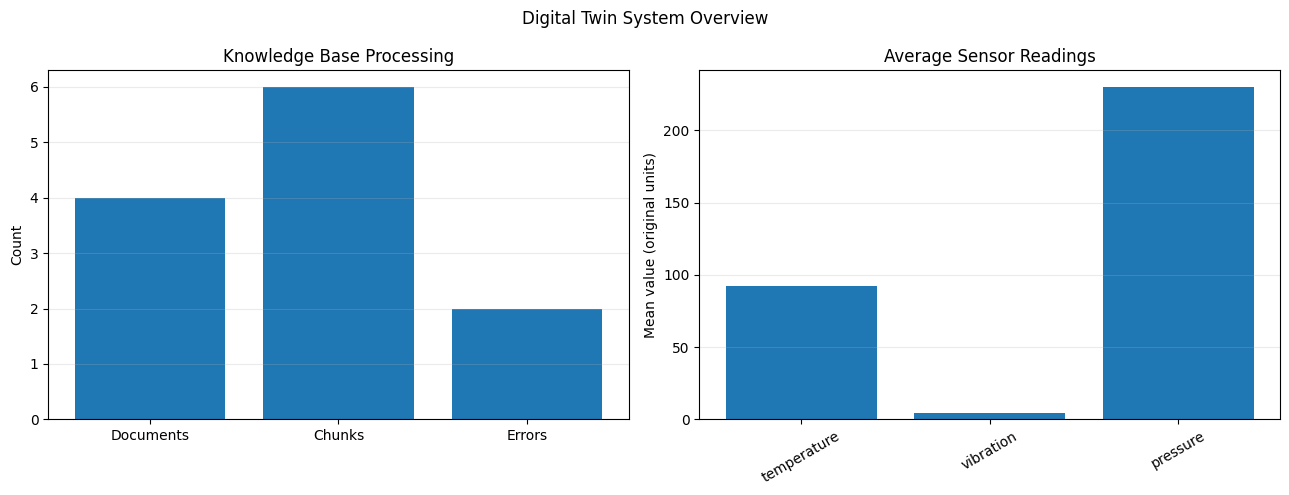

In [8]:
import json
import logging
import math
import re
import sys
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, List, Optional


# ============================================================
# DIGITAL TWIN PRODUCTION SYSTEM
# ============================================================

class ProductionSystem:
    """
    Digital Twin Document Processing System.

    Features
    --------
    - Document Ingestion from strings, dictionaries and lists.
    - Optional loading of TXT, Markdown, JSON, CSV and log files.
    - Unicode normalisation and whitespace cleaning.
    - Extraction of emails, URLs, dates, error codes and measurements.
    - Word-based chunking with overlap and source metadata.
    - Keyword-based retrieval for a basic RAG workflow.
    - Sensor reading validation and anomaly detection.
    - Logging, error reporting and processing statistics.
    - Context-window budgeting and token-count estimation.

    Important
    ---------
    Token counts are estimates. Keyword retrieval is not semantic search.
    Sensor anomaly thresholds are configurable illustrative rules, not
    a substitute for equipment-specific engineering limits.
    """

    SUPPORTED_EXTENSIONS = {".txt", ".md", ".markdown", ".json", ".csv", ".log"}

    def __init__(
        self,
        chunk_size: int = 100,
        overlap: int = 10,
        anomaly_thresholds: Optional[Dict[str, float]] = None,
        max_file_bytes: int = 5_000_000,
        log_level: int = logging.INFO,
        log_file: Optional[str] = None,
    ):
        # Validate configuration
        if isinstance(chunk_size, bool) or not isinstance(chunk_size, int):
            raise TypeError("chunk_size must be an integer.")
        if chunk_size < 1:
            raise ValueError("chunk_size must be at least 1.")

        if isinstance(overlap, bool) or not isinstance(overlap, int):
            raise TypeError("overlap must be an integer.")
        if not 0 <= overlap < chunk_size:
            raise ValueError(
                "overlap must be non-negative and smaller than chunk_size."
            )

        if isinstance(max_file_bytes, bool) or not isinstance(max_file_bytes, int):
            raise TypeError("max_file_bytes must be an integer.")
        if max_file_bytes < 1:
            raise ValueError("max_file_bytes must be at least 1.")

        if not isinstance(log_level, int):
            raise TypeError("log_level must be an integer logging level.")

        self.chunk_size = chunk_size
        self.overlap = overlap
        self.max_file_bytes = max_file_bytes
        self.anomaly_thresholds = anomaly_thresholds or {
            "temperature": 80.0,
            "vibration": 10.0,
            "pressure": 200.0,
        }

        for metric, threshold in self.anomaly_thresholds.items():
            if (
                not isinstance(metric, str)
                or not metric.strip()
                or isinstance(threshold, bool)
                or not isinstance(threshold, (int, float))
                or not math.isfinite(threshold)
            ):
                raise ValueError(
                    "Anomaly thresholds must map non-empty metric names "
                    "to finite numeric values."
                )

        # Configure a dedicated logger without duplicating handlers
        self.logger = logging.getLogger(f"DigitalTwin.{id(self)}")
        self.logger.setLevel(log_level)
        self.logger.propagate = False

        formatter = logging.Formatter(
            "%(asctime)s | %(levelname)s | %(name)s | %(message)s"
        )

        console_handler = logging.StreamHandler(sys.stderr)
        console_handler.setFormatter(formatter)
        self.logger.addHandler(console_handler)

        if log_file:
            try:
                file_handler = logging.FileHandler(
                    log_file, encoding="utf-8"
                )
                file_handler.setFormatter(formatter)
                self.logger.addHandler(file_handler)
            except OSError as exc:
                self.logger.warning(
                    "Could not initialise file logging: %s", exc
                )

        # In-memory stores
        self.documents: List[Dict[str, Any]] = []
        self.chunks: List[Dict[str, Any]] = []
        self.sensor_readings: List[Dict[str, Any]] = []
        self.errors: List[Dict[str, Any]] = []
        self.history: List[Dict[str, Any]] = []
        self._next_document_id = 1

        self.logger.info("Digital Twin ProductionSystem initialised.")

    # --------------------------------------------------------
    # 1. Text cleaning
    # --------------------------------------------------------
    @staticmethod
    def clean_text(text: str) -> str:
        """Normalise Unicode and whitespace without removing technical symbols."""
        if not isinstance(text, str):
            raise TypeError("Text to clean must be a string.")

        text = unicodedata.normalize("NFC", text)
        text = text.replace("\r\n", "\n").replace("\r", "\n")
        text = "".join(
            char for char in text
            if char in "\n\t" or unicodedata.category(char) != "Cc"
        )

        lines = [
            re.sub(r"[ \t]+", " ", line).strip()
            for line in text.split("\n")
        ]

        return re.sub(r"\n{3,}", "\n\n", "\n".join(lines)).strip()

    # --------------------------------------------------------
    # 2. Structured information extraction
    # --------------------------------------------------------
    @staticmethod
    def extract_information(text: str) -> Dict[str, List[str]]:
        """Extract common technical and operational references."""
        patterns = {
            "emails": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
            "urls": r"https?://[^\s<>\]\[\"']+",
            "dates": r"\b\d{4}-\d{2}-\d{2}\b",
            "times": r"\b\d{1,2}:\d{2}(?::\d{2})?\b",
            "hashtags": r"(?<!\w)#[A-Za-z0-9_]+",
            "mentions": r"(?<!\w)@[A-Za-z0-9_]+",
            "error_codes": r"\bERR[-_]?\d+\b",
            "measurements": (
                r"\b\d+(?:\.\d+)?\s?"
                r"(?:ms|seconds?|minutes?|hours?|%|GB|MB|KB|"
                r"°C|Celsius|bar|kPa|MPa|rpm|mm/s)\b"
            ),
            "identifiers": (
                r"\b(?:sensor|machine|asset|device|equipment)"
                r"[-_ ]?[A-Za-z0-9]+\b"
            ),
        }

        extracted = {}
        for key, pattern in patterns.items():
            matches = re.findall(pattern, text, flags=re.IGNORECASE)
            extracted[key] = list(dict.fromkeys(matches))

        return extracted

    # --------------------------------------------------------
    # 3. Token estimation and context budgeting
    # --------------------------------------------------------
    @staticmethod
    def estimate_tokens(text: str) -> int:
        """
        Rough token estimate only.

        Replace with the actual tokenizer used by your target language
        model before relying on token budgets in production.
        """
        if not isinstance(text, str):
            raise TypeError("Token estimation requires a string.")

        if not text.strip():
            return 0

        # A deliberately simple approximation for mixed technical text.
        return max(1, math.ceil(len(text) / 4))

    @staticmethod
    def context_budget(
        context_window: int,
        reserved_output: int,
        system_prompt_tokens: int = 0,
    ) -> Dict[str, int]:
        """Calculate the approximate input budget for an LLM."""
        values = {
            "context_window": context_window,
            "reserved_output": reserved_output,
            "system_prompt_tokens": system_prompt_tokens,
        }

        for name, value in values.items():
            if isinstance(value, bool) or not isinstance(value, int):
                raise TypeError(f"{name} must be an integer.")
            if value < 0:
                raise ValueError(f"{name} cannot be negative.")

        if context_window < 1:
            raise ValueError("context_window must be at least 1.")

        available = context_window - reserved_output - system_prompt_tokens
        if available < 0:
            raise ValueError(
                "Reserved output and system prompt exceed the context window."
            )

        return {
            **values,
            "available_input_tokens": available,
        }

    # --------------------------------------------------------
    # 4. Structure-aware document chunking
    # --------------------------------------------------------
    def chunk_text(
        self,
        text: str,
        document_id: str,
        metadata: Optional[Dict[str, Any]] = None,
    ) -> List[Dict[str, Any]]:
        """
        Chunk text by words, preferring paragraph boundaries when practical.

        Oversized paragraphs are split using a sliding window. Each chunk
        keeps its document ID, metadata, word count and estimated token count.
        """
        text = self.clean_text(text)
        if not text:
            return []

        metadata = metadata or {}
        paragraphs = [
            paragraph.strip()
            for paragraph in re.split(r"\n\s*\n", text)
            if paragraph.strip()
        ]

        raw_chunks = []
        current_words = []

        def flush():
            if current_words:
                raw_chunks.append(" ".join(current_words))
                current_words.clear()

        for paragraph in paragraphs:
            words = paragraph.split()

            if len(words) > self.chunk_size:
                flush()
                step = self.chunk_size - self.overlap

                for start in range(0, len(words), step):
                    part = words[start:start + self.chunk_size]
                    if part:
                        raw_chunks.append(" ".join(part))
                    if start + self.chunk_size >= len(words):
                        break
                continue

            if len(current_words) + len(words) > self.chunk_size:
                flush()

            current_words.extend(words)

        flush()

        result = []
        for index, chunk in enumerate(raw_chunks, start=1):
            result.append({
                "document_id": document_id,
                "chunk_id": f"{document_id}_chunk_{index}",
                "text": chunk,
                "metadata": metadata.copy(),
                "word_count": len(chunk.split()),
                "estimated_tokens": self.estimate_tokens(chunk),
            })

        return result

    # --------------------------------------------------------
    # 5. Optional file loading
    # --------------------------------------------------------
    def load_file(self, file_path: str) -> Dict[str, Any]:
        """Load a supported local document file."""
        if not isinstance(file_path, str) or not file_path.strip():
            raise ValueError("file_path must be a non-empty string.")

        path = Path(file_path)

        if path.suffix.lower() not in self.SUPPORTED_EXTENSIONS:
            raise ValueError(
                f"Unsupported file type ‘{path.suffix}’. "
                f"Supported extensions: {sorted(self.SUPPORTED_EXTENSIONS)}"
            )

        try:
            if not path.is_file():
                raise FileNotFoundError(f"File not found: {path}")

            size = path.stat().st_size
            if size > self.max_file_bytes:
                raise ValueError(
                    f"File is {size} bytes; limit is {self.max_file_bytes}."
                )

            content = path.read_text(encoding="utf-8")

            if path.suffix.lower() == ".json":
                # Validate JSON syntax while preserving the original content.
                json.loads(content)

            return {
                "text": content,
                "metadata": {
                    "source": str(path),
                    "file_type": path.suffix.lower(),
                    "file_size_bytes": size,
                },
            }

        except (OSError, UnicodeError, json.JSONDecodeError) as exc:
            self.logger.exception("File loading failed: %s", path)
            raise ValueError(
                f"Could not load ‘{path}’: {exc}"
            ) from exc

    # --------------------------------------------------------
    # 6. Document ingestion
    # --------------------------------------------------------
    def ingest(self, input_data: Any) -> Dict[str, Any]:
        """
        Ingest one document, a document dictionary, or a list of documents.

        Dictionary format:
            {"text": "...", "metadata": {"source": "sensor.log"}}

        The ‘content’ key can be used instead of ‘text’.
        """
        if isinstance(input_data, str):
            items = [{"text": input_data, "metadata": {}}]
        elif isinstance(input_data, dict):
            items = [input_data]
        elif isinstance(input_data, list):
            items = input_data
        else:
            raise TypeError(
                "Input must be a string, dictionary or list of documents."
            )

        if not items:
            raise ValueError("The document list cannot be empty.")

        added_documents = []
        added_chunks = []
        failures = []

        for index, item in enumerate(items):
            try:
                if isinstance(item, str):
                    raw_text = item
                    metadata = {}
                elif isinstance(item, dict):
                    raw_text = item.get("text", item.get("content"))
                    metadata = item.get("metadata", {})

                    if not isinstance(metadata, dict):
                        raise TypeError("Document metadata must be a dictionary.")
                else:
                    raise TypeError(
                        "Each item must be a string or a document dictionary."
                    )

                if not isinstance(raw_text, str):
                    raise TypeError(
                        "Each document needs string ‘text’ or ‘content’."
                    )

                cleaned = self.clean_text(raw_text)
                if not cleaned:
                    raise ValueError("Document text cannot be empty.")

                document_id = f"doc_{self._next_document_id}"

                document = {
                    "document_id": document_id,
                    "text": cleaned,
                    "metadata": metadata.copy(),
                    "word_count": len(cleaned.split()),
                    "estimated_tokens": self.estimate_tokens(cleaned),
                    "extracted_information": self.extract_information(cleaned),
                    "ingested_at": datetime.now(timezone.utc).isoformat(),
                }

                chunks = self.chunk_text(
                    cleaned, document_id, metadata
                )

                document["chunk_count"] = len(chunks)

                # Commit only after validation and chunking succeed.
                self.documents.append(document)
                self.chunks.extend(chunks)
                added_documents.append(document)
                added_chunks.extend(chunks)
                self._next_document_id += 1

                self.logger.info(
                    "Ingested %s with %s chunks.",
                    document_id,
                    len(chunks),
                )

            except (TypeError, ValueError) as exc:
                failure = {
                    "item_index": index,
                    "error": str(exc),
                }
                failures.append(failure)
                self.errors.append(failure)
                self.logger.warning(
                    "Document item %s rejected: %s", index, exc
                )

        result = {
            "status": (
                "success" if added_documents and not failures
                else "partial_success" if added_documents
                else "failed"
            ),
            "documents_added": len(added_documents),
            "chunks_added": len(added_chunks),
            "failures": failures,
            "document_ids": [
                document["document_id"] for document in added_documents
            ],
        }

        self.history.append({
            "operation": "ingest",
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "result": result.copy(),
        })

        if not added_documents:
            self.logger.error("No valid documents were ingested.")

        return result

    # --------------------------------------------------------
    # 7. Digital twin sensor ingestion and anomaly detection
    # --------------------------------------------------------
    def ingest_sensor_readings(self, readings: Any) -> Dict[str, Any]:
        """
        Validate sensor readings and flag values above configured thresholds.

        Example:
            {
                "asset_id": "MACHINE-01",
                "sensor": "temperature",
                "value": 92.5,
                "unit": "°C"
            }
        """
        if isinstance(readings, dict):
            readings = [readings]

        if not isinstance(readings, list):
            raise TypeError("Sensor readings must be a dictionary or list.")

        if not readings:
            raise ValueError("Sensor readings cannot be empty.")

        accepted = []
        failures = []

        for index, reading in enumerate(readings):
            try:
                if not isinstance(reading, dict):
                    raise TypeError("Each sensor reading must be a dictionary.")

                asset_id = reading.get("asset_id")
                sensor = reading.get("sensor")
                value = reading.get("value")

                if not isinstance(asset_id, str) or not asset_id.strip():
                    raise ValueError("asset_id must be a non-empty string.")

                if not isinstance(sensor, str) or not sensor.strip():
                    raise ValueError("sensor must be a non-empty string.")

                if (
                    isinstance(value, bool)
                    or not isinstance(value, (int, float))
                    or not math.isfinite(value)
                ):
                    raise ValueError("Sensor value must be a finite number.")

                sensor_key = sensor.strip().lower()
                threshold = self.anomaly_thresholds.get(sensor_key)
                anomaly = threshold is not None and value > threshold

                record = {
                    "asset_id": asset_id.strip(),
                    "sensor": sensor_key,
                    "value": float(value),
                    "unit": reading.get("unit", ""),
                    "threshold": threshold,
                    "anomaly": anomaly,
                    "recorded_at": datetime.now(timezone.utc).isoformat(),
                }

                accepted.append(record)
                self.sensor_readings.append(record)

                if anomaly:
                    self.logger.warning(
                        "Threshold exceeded: asset=%s sensor=%s value=%s "
                        "threshold=%s",
                        asset_id, sensor_key, value, threshold,
                    )
                else:
                    self.logger.debug(
                        "Sensor reading accepted: %s", record
                    )

            except (TypeError, ValueError) as exc:
                failure = {"item_index": index, "error": str(exc)}
                failures.append(failure)
                self.errors.append(failure)
                self.logger.warning(
                    "Sensor reading %s rejected: %s", index, exc
                )

        status = (
            "success" if accepted and not failures
            else "partial_success" if accepted
            else "failed"
        )

        result = {
            "status": status,
            "readings_accepted": len(accepted),
            "anomalies_detected": sum(r["anomaly"] for r in accepted),
            "failures": failures,
            "readings": accepted,
        }

        self.history.append({
            "operation": "sensor_ingestion",
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "result": result.copy(),
        })

        return result

    # --------------------------------------------------------
    # 8. Basic RAG retrieval
    # --------------------------------------------------------
    @staticmethod
    def _terms(text: str) -> set:
        """Tokenise words while preserving technical identifiers as terms."""
        return set(re.findall(r"\b[\w-]+\b", text.lower()))

    def retrieve(
        self,
        query: str,
        top_k: int = 3,
    ) -> Dict[str, Any]:
        """Retrieve chunks using keyword overlap, with source metadata."""
        if not isinstance(query, str) or not query.strip():
            raise ValueError("query must be a non-empty string.")

        if isinstance(top_k, bool) or not isinstance(top_k, int):
            raise TypeError("top_k must be an integer.")

        if top_k < 1:
            raise ValueError("top_k must be at least 1.")

        if not self.chunks:
            return {
                "status": "empty_knowledge_base",
                "query": query,
                "results": [],
                "message": "Ingest documents before searching.",
            }

        query_terms = self._terms(query)
        stopwords = {
            "a", "an", "the", "is", "are", "was", "were", "and", "or",
            "of", "to", "in", "on", "for", "with", "how", "what", "does",
            "do", "can", "use", "using",
        }
        query_terms -= stopwords

        if not query_terms:
            raise ValueError(
                "Query contains no searchable terms after filtering."
            )

        ranked = []

        for chunk in self.chunks:
            chunk_terms = self._terms(chunk["text"])
            matched = sorted(query_terms.intersection(chunk_terms))

            if matched:
                result = chunk.copy()
                result["matched_terms"] = matched
                result["score"] = round(
                    len(matched) / len(query_terms), 3
                )
                ranked.append(result)

        ranked.sort(
            key=lambda item: (
                item["score"],
                len(item["matched_terms"]),
                item["chunk_id"],
            ),
            reverse=True,
        )

        result = {
            "status": "success" if ranked else "no_matches",
            "query": query,
            "results": ranked[:top_k],
            "message": (
                "Keyword matches found." if ranked
                else "No matching chunks were found."
            ),
        }

        self.history.append({
            "operation": "retrieve",
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "query": query,
            "results_count": len(result["results"]),
        })

        self.logger.info(
            "Retrieval completed: %s results for query %r.",
            len(result["results"]), query,
        )
        return result

    # --------------------------------------------------------
    # 9. Unified processing interface
    # --------------------------------------------------------
    def process(self, input_data: Any) -> Dict[str, Any]:
        """
        Main entry point.

        Accepted formats:
          {"type": "documents", "data": [... ]}
          {"type": "sensors", "data": [... ]}
          {"type": "query", "query": "...", "top_k": 3}
          {"type": "file", "path": "equipment.log"}

        Plain strings, document dictionaries and lists are treated as
        documents unless a specific type is supplied.
        """
        try:
            if isinstance(input_data, dict) and "type" in input_data:
                operation = input_data["type"]

                if operation == "documents":
                    return self.ingest(input_data.get("data"))

                if operation == "sensors":
                    return self.ingest_sensor_readings(
                        input_data.get("data")
                    )

                if operation == "query":
                    return self.retrieve(
                        input_data.get("query"),
                        input_data.get("top_k", 3),
                    )

                if operation == "file":
                    file_document = self.load_file(input_data.get("path"))
                    return self.ingest(file_document)

                raise ValueError(
                    "Unknown operation type. Use documents, sensors, "
                    "query or file."
                )

            return self.ingest(input_data)

        except (TypeError, ValueError, OSError) as exc:
            self.logger.error("Processing failed: %s", exc)
            return {
                "status": "error",
                "error_type": type(exc).__name__,
                "message": str(exc),
            }

        except Exception as exc:
            # Preserve a diagnostic traceback for unexpected failures.
            self.logger.exception("Unexpected processing failure.")
            return {
                "status": "error",
                "error_type": type(exc).__name__,
                "message": "Unexpected processing error. Check the logs.",
            }

    # --------------------------------------------------------
    # 10. Monitoring, statistics and debugging
    # --------------------------------------------------------
    def get_stats(self) -> Dict[str, Any]:
        """Return current knowledge-base and sensor statistics."""
        sensor_counts = Counter(
            reading["sensor"] for reading in self.sensor_readings
        )

        return {
            "documents": len(self.documents),
            "chunks": len(self.chunks),
            "total_words": sum(
                doc["word_count"] for doc in self.documents
            ),
            "estimated_tokens": sum(
                doc["estimated_tokens"] for doc in self.documents
            ),
            "sensor_readings": len(self.sensor_readings),
            "sensor_types": dict(sensor_counts),
            "anomalies": sum(
                reading["anomaly"] for reading in self.sensor_readings
            ),
            "errors_recorded": len(self.errors),
            "operations_recorded": len(self.history),
        }

    def debug_summary(self) -> Dict[str, Any]:
        """Return a concise diagnostic summary."""
        summary = {
            "configuration": {
                "chunk_size": self.chunk_size,
                "overlap": self.overlap,
                "anomaly_thresholds": self.anomaly_thresholds.copy(),
            },
            "stats": self.get_stats(),
            "recent_operations": self.history[-5:],
            "recent_errors": self.errors[-5:],
            "recent_documents": [
                {
                    "document_id": doc["document_id"],
                    "word_count": doc["word_count"],
                    "chunk_count": doc["chunk_count"],
                }
                for doc in self.documents[-5:]
            ],
        }

        self.logger.debug(
            "Debug summary: %s",
            json.dumps(summary, default=str),
        )
        return summary

    # --------------------------------------------------------
    # 11. Visualisation
    # --------------------------------------------------------
    def visualize_results(self, show: bool = True):
        """
        Plot document/chunk statistics and sensor values.

        Returns the Matplotlib figure for saving or further customisation.
        """
        import matplotlib.pyplot as plt

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))

        # Panel A: documents and chunks
        labels = ["Documents", "Chunks", "Errors"]
        values = [
            len(self.documents),
            len(self.chunks),
            len(self.errors),
        ]

        axes[0].bar(labels, values)
        axes[0].set_title("Knowledge Base Processing")
        axes[0].set_ylabel("Count")
        axes[0].grid(axis="y", alpha=0.25)

        # Panel B: sensor readings by type
        sensor_groups = {}
        for reading in self.sensor_readings:
            sensor_groups.setdefault(reading["sensor"], []).append(
                reading["value"]
            )

        if sensor_groups:
            names = list(sensor_groups.keys())
            means = [
                sum(sensor_groups[name]) / len(sensor_groups[name])
                for name in names
            ]
            axes[1].bar(names, means)
            axes[1].set_title("Average Sensor Readings")
            axes[1].set_ylabel("Mean value (original units)")
            axes[1].tick_params(axis="x", rotation=30)
            axes[1].grid(axis="y", alpha=0.25)
        else:
            axes[1].text(
                0.5, 0.5, "No sensor readings available",
                ha="center", va="center",
                transform=axes[1].transAxes,
            )
            axes[1].set_title("Average Sensor Readings")

        fig.suptitle("Digital Twin System Overview")
        fig.tight_layout()

        if show:
            plt.show()

        return fig

    def close(self):
        """Close this instance's logging handlers."""
        for handler in self.logger.handlers[:]:
            handler.close()
            self.logger.removeHandler(handler)


# ============================================================
# COMPREHENSIVE TESTS AND DEMONSTRATION
# ============================================================

def run_tests():
    import tempfile

    system = ProductionSystem(
        chunk_size=12,
        overlap=2,
        anomaly_thresholds={
            "temperature": 80.0,
            "vibration": 10.0,
            "pressure": 200.0,
        },
        log_level=logging.WARNING,
    )

    # Test 1: Text document ingestion
    docs = [
        {
            "text": (
                "Machine-01 temperature reached 92 °C on 2026-10-14. "
                "Error ERR-404 reported. Contact support@example.com."
            ),
            "metadata": {"source": "machine_01.log", "asset": "Machine-01"},
        },
        (
            "Predictive maintenance uses sensor data to identify "
            "equipment faults before a machine fails."
        ),
        (
            "A digital twin mirrors a physical asset using operational "
            "data and a virtual representation."
        ),
    ]

    ingestion = system.process({
        "type": "documents",
        "data": docs,
    })

    assert ingestion["status"] == "success", ingestion
    assert ingestion["documents_added"] == 3
    assert ingestion["chunks_added"] >= 3

    # Test 2: Structured extraction
    first_doc = system.documents[0]
    assert "support@example.com" in first_doc["extracted_information"]["emails"]
    assert "ERR-404" in first_doc["extracted_information"]["error_codes"]
    assert "2026-10-14" in first_doc["extracted_information"]["dates"]

    # Test 3: Keyword retrieval
    retrieval = system.process({
        "type": "query",
        "query": "predictive maintenance sensor data",
        "top_k": 3,
    })

    assert retrieval["status"] == "success", retrieval
    assert len(retrieval["results"]) > 0

    # Test 4: Sensor ingestion and anomaly detection
    sensor_result = system.process({
        "type": "sensors",
        "data": [
            {
                "asset_id": "Machine-01",
                "sensor": "temperature",
                "value": 92.0,
                "unit": "°C",
            },
            {
                "asset_id": "Machine-01",
                "sensor": "vibration",
                "value": 4.2,
                "unit": "mm/s",
            },
            {
                "asset_id": "Machine-02",
                "sensor": "pressure",
                "value": 230.0,
                "unit": "kPa",
            },
        ],
    })

    assert sensor_result["status"] == "success"
    assert sensor_result["anomalies_detected"] == 2

    # Test 5: Invalid sensor reading is handled
    invalid_sensor = system.process({
        "type": "sensors",
        "data": [
            {"asset_id": "Machine-03", "sensor": "temperature", "value": float("nan")}
        ],
    })

    assert invalid_sensor["status"] == "failed"
    assert len(invalid_sensor["failures"]) == 1

    # Test 6: Unsupported operation
    invalid_operation = system.process({
        "type": "unknown_operation",
        "data": [],
    })

    assert invalid_operation["status"] == "error"

    # Test 7: Empty knowledge base retrieval
    empty_system = ProductionSystem(log_level=logging.CRITICAL)
    empty_search = empty_system.process({
        "type": "query",
        "query": "temperature",
    })
    assert empty_search["status"] == "empty_knowledge_base"
    empty_system.close()

    # Test 8: File loading
    with tempfile.TemporaryDirectory() as temp_dir:
        test_path = Path(temp_dir) / "equipment.log"
        test_path.write_text(
            "Machine-04 vibration measured 3.5 mm/s.",
            encoding="utf-8",
        )

        file_result = system.process({
            "type": "file",
            "path": str(test_path),
        })

        assert file_result["status"] == "success", file_result

    # Test 9: Context-window budgeting
    budget = system.context_budget(
        context_window=8192,
        reserved_output=1024,
        system_prompt_tokens=500,
    )
    assert budget["available_input_tokens"] == 6668

    # Test 10: Chunk overlap
    overlap_system = ProductionSystem(
        chunk_size=4,
        overlap=1,
        log_level=logging.CRITICAL,
    )
    chunks = overlap_system.chunk_text(
        "one two three four five six seven",
        "test_doc",
    )

    assert len(chunks) == 2
    assert chunks[0]["text"].split()[-1] == chunks[1]["text"].split()[0]
    overlap_system.close()

    # Test 11: Invalid configuration
    try:
        ProductionSystem(chunk_size=5, overlap=5)
        raise AssertionError("Invalid overlap should have raised ValueError.")
    except ValueError:
        pass

    # Test 12: Empty document rejection
    rejected = system.process("    ")
    assert rejected["status"] == "failed"

    # Test 13: Visualisation
    figure = system.visualize_results(show=False)
    assert figure is not None

    # Display current statistics and debug information
    print("All tests passed.")
    print("\nSystem statistics:")
    print(json.dumps(system.get_stats(), indent=2))
    print("\nDebug summary:")
    print(json.dumps(system.debug_summary(), indent=2, default=str))

    # Show the chart
    import matplotlib.pyplot as plt
    plt.show()

    system.close()


if __name__ == "__main__":
    run_tests()


---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code